# Recurrence-free survival in GBSG2

Walkthrough of `analysis.py`: Kaplan-Meier and log-rank comparisons, Cox proportional hazards models, the proportional-hazards check that motivates stratifying by grade, discrimination (Harrell's C) and sensitivity analyses for the hormone therapy hazard ratio. All logic lives in `analysis.py`; this notebook calls it and shows the results.

In [1]:
import pandas as pd
import analysis

pd.set_option("display.precision", 3)
df = analysis.load_data()
metrics = analysis.run()  # writes outputs/ and figures/
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
horTh,686,2,no,440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,686.0,NaN,NaN,NaN,53.052,10.121,21.0,46.0,53.0,61.0,80.0
menostat,686,2,Post,396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tsize,686.0,NaN,NaN,NaN,29.329,14.296,3.0,20.0,25.0,35.0,120.0
tgrade,686,3,II,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pnodes,686.0,NaN,NaN,NaN,5.01,5.475,1.0,1.0,3.0,7.0,51.0
progrec,686.0,NaN,NaN,NaN,109.996,202.332,0.0,7.0,32.5,131.75,2380.0
estrec,686.0,NaN,NaN,NaN,96.252,153.084,0.0,8.0,36.0,114.0,1144.0
time_days,686.0,NaN,NaN,NaN,1124.49,642.792,8.0,567.75,1084.0,1684.75,2659.0
event,686.0,NaN,NaN,NaN,0.436,0.496,0.0,0.0,0.0,1.0,1.0


## Kaplan-Meier and log-rank

In [2]:
pd.read_csv("outputs/km_summary.csv")

,group,level,n,events,median_days,median_ci_low,median_ci_high,rfs_5y,rfs_5y_ci_low,rfs_5y_ci_high
0,overall,all,686,299,1807.0,1528.0,2018.0,0.492,0.446,0.536
1,horTh,no,440,205,1528.0,1280.0,1814.0,0.437,0.378,0.494
2,horTh,yes,246,94,2018.0,1918.0,NaN,0.581,0.507,0.648
3,tgrade,I,81,18,NaN,1990.0,NaN,0.744,0.614,0.836
4,tgrade,II,444,202,1730.0,1481.0,2018.0,0.470,0.413,0.524
5,tgrade,III,161,79,1337.0,956.0,2034.0,0.435,0.339,0.527


In [3]:
pd.read_csv("outputs/logrank_tests.csv")

,group,chisq,df,p_value
0,horTh,8.565,1,3.427e-03
1,tgrade,21.094,2,2.627e-05


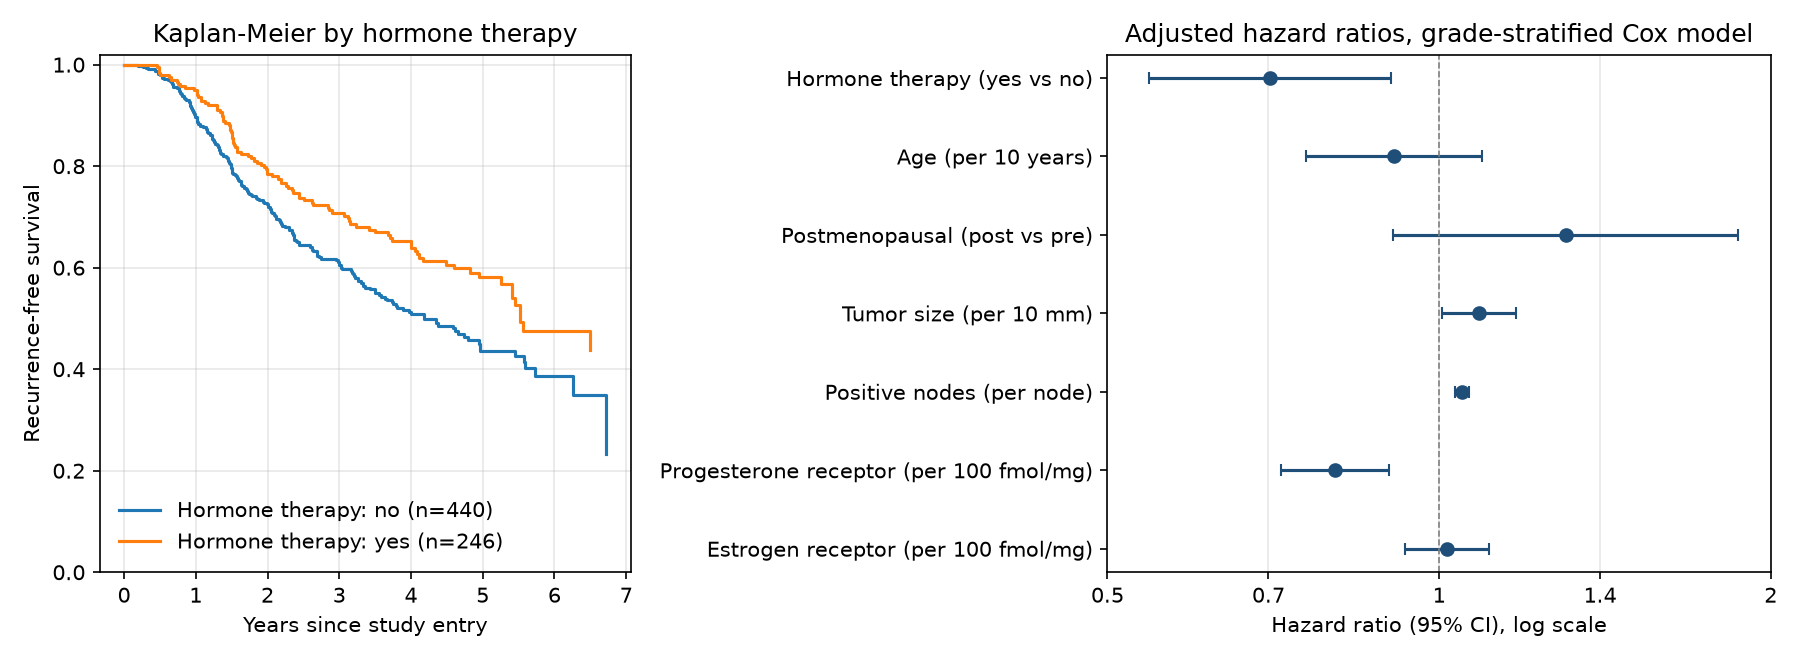

In [4]:
from IPython.display import Image
Image("figures/summary.png")

## Proportional hazards check

Grambsch-Therneau score test on log(time), identical to `survival::cox.zph(fit, transform = "log")`. Grade fails in the original model, so the primary model stratifies the baseline hazard by grade. Age, menopausal status and estrogen receptor still show trends; they are handled in the time-varying sensitivity model below.

In [5]:
pd.read_csv("outputs/ph_diagnostics.csv")

,term,chisq,df,p_value,model
0,horTh_yes,0.369,1,0.543,original_ordinal_grade
1,age,9.352,1,0.002,original_ordinal_grade
2,menostat_Post,5.315,1,0.021,original_ordinal_grade
3,tsize,0.424,1,0.515,original_ordinal_grade
4,grade_ord,8.451,1,0.004,original_ordinal_grade
5,pnodes,0.435,1,0.510,original_ordinal_grade
6,progrec,3.746,1,0.053,original_ordinal_grade
7,estrec,6.430,1,0.011,original_ordinal_grade
8,GLOBAL,21.023,8,0.007,original_ordinal_grade
9,horTh_yes,0.101,1,0.750,primary_grade_stratified


## Hazard ratios

In [6]:
coef = pd.read_csv("outputs/cox_coefficients.csv")
coef.query("model == 'primary_grade_stratified'")[["term", "report_unit", "hr_report", "ci_low_report", "ci_high_report", "p_value"]]

,term,report_unit,hr_report,ci_low_report,ci_high_report,p_value
8,horTh_yes,yes vs no,0.702,0.545,0.905,6.289e-03
9,age,per 10 years,0.910,0.758,1.093,3.132e-01
10,menostat_Post,post vs pre,1.303,0.908,1.869,1.505e-01
11,tsize,per 10 mm,1.087,1.006,1.174,3.420e-02
12,pnodes,per node,1.049,1.033,1.064,2.409e-10
13,progrec,per 100 fmol/mg,0.804,0.719,0.900,1.481e-04
14,estrec,per 100 fmol/mg,1.016,0.931,1.109,7.214e-01


## Discrimination

Apparent Harrell's C and the bootstrap optimism-corrected value for the primary model (200 resamples, fixed seed).

In [7]:
metrics["concordance"]

{'original_apparent': 0.6879809426475892,
 'primary': {'apparent': 0.6737101920414184,
  'optimism': 0.012056722760768584,
  'corrected': 0.6616534692806497,
  'n_boot': 200,
  'seed': 20261023}}

## Functional form and sensitivity

Likelihood-ratio tests of a natural cubic spline against each linear term, then the hormone therapy hazard ratio across alternative specifications.

In [8]:
pd.read_csv("outputs/functional_form_diagnostics.csv")

,term,lr_chisq,df,p_value
0,age,16.645,2,2.430e-04
1,tsize,6.991,2,3.033e-02
2,pnodes,28.031,2,8.188e-07
3,progrec,11.804,2,2.734e-03
4,estrec,1.788,2,4.090e-01


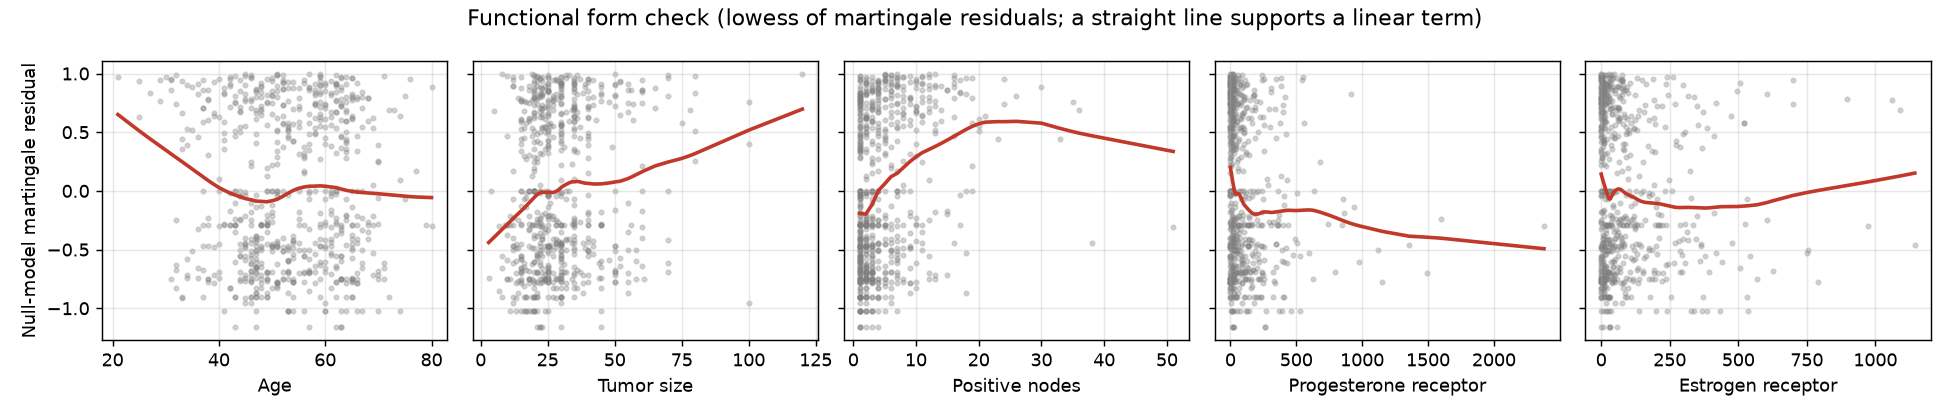

In [9]:
Image("outputs/figures/functional_form.png")

In [10]:
pd.read_csv("outputs/hormone_therapy_sensitivity.csv")

,model,hr,ci_low,ci_high,p_value,loglik,c_index_apparent
0,"original: ordinal grade, all terms linear",0.714,0.554,0.919,8.934e-03,-1737.261,0.688
1,primary: grade-stratified,0.702,0.545,0.905,6.289e-03,-1507.101,0.674
2,"primary + age, menopause, ER x log(t)",0.711,0.551,0.917,8.547e-03,-1502.003,NaN
3,primary + natural splines for all continuous t...,0.625,0.484,0.808,3.400e-04,-1475.275,0.702
